# DASC 5420: Assignment 2 (Python Code)

**Student Name:** Asmita Bashyal

**Student Number:** T00781099



In [6]:
import numpy as np
from matplotlib.pyplot import subplots

## Question 2 (d), (e), (f)
$P(\text{observation } j \text{ is in the bootstrap sample}) = 1-(1-1/n)^n$

In [7]:
for n in [5, 100, 10000]:
    prob = 1 - (1 - 1/n)**n
    print("n =", n, " P(observation j is in the bootstrap sample) =", round(prob, 4))

print("1 - e^(-1) =", round(1 - np.exp(-1), 4))

n = 5  P(observation j is in the bootstrap sample) = 0.6723
n = 100  P(observation j is in the bootstrap sample) = 0.634
n = 10000  P(observation j is in the bootstrap sample) = 0.6321
1 - e^(-1) = 0.6321


## Question 2 (g): plot for n = 1 to 100,000

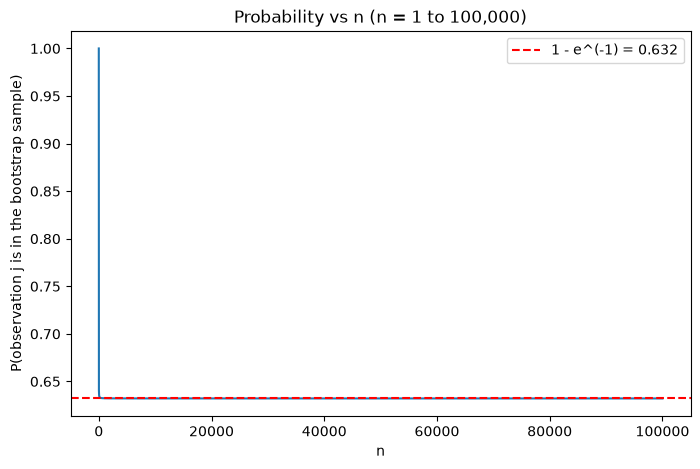

In [8]:
n = np.arange(1, 100001)          # n = 1, 2, 3, ..., 100000
prob = 1 - (1 - 1/n)**n           # probability for every n at once

fig, ax = subplots(figsize=(8, 5))
ax.plot(n, prob)
ax.axhline(1 - np.exp(-1), color='red', linestyle='--', label='1 - e^(-1) = 0.632')
ax.set_xlabel('n')
ax.set_ylabel('P(observation j is in the bootstrap sample)')
ax.set_title('Probability vs n (n = 1 to 100,000)')
ax.legend();

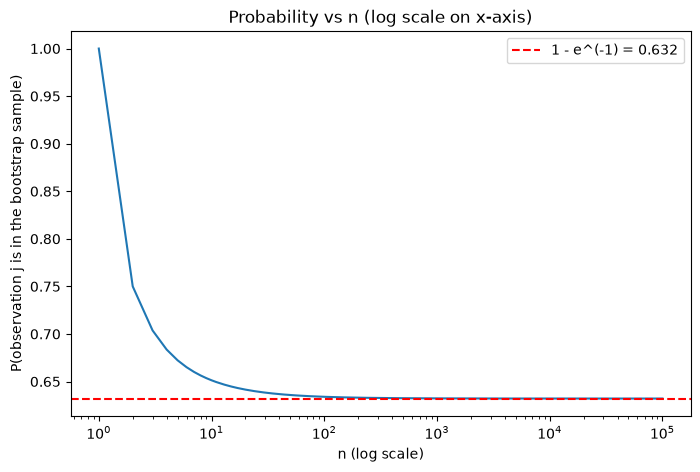

In [9]:
# Same curve with a log-scale x-axis, so small n is easier to see
fig, ax = subplots(figsize=(8, 5))
ax.plot(n, prob)
ax.axhline(1 - np.exp(-1), color='red', linestyle='--', label='1 - e^(-1) = 0.632')
ax.set_xscale('log')
ax.set_xlabel('n (log scale)')
ax.set_ylabel('P(observation j is in the bootstrap sample)')
ax.set_title('Probability vs n (log scale on x-axis)')
ax.legend();

**Comment.** At $n=1$ the probability is 1. It drops quickly as $n$ increases, then levels off at $1-e^{-1}\approx0.632$ from about $n=100$ onward. On average, about 63.2% of the observations appear at least once in a bootstrap sample, and about 36.8% are out of bag.

## Question 2 (h): simulation with n = 100 and j = 4


In [10]:
rng = np.random.default_rng(10)
B = 10000                         # number of bootstrap samples
n = 100                           # size of each bootstrap sample
store = np.empty(B)

for b in range(B):
    sample = rng.choice(n, n, replace=True)   # one bootstrap sample
    store[b] = np.sum(sample == 4) > 0        # 1 if observation 4 is in it, else 0

print("Simulated probability:", np.mean(store))
print("Theoretical probability:", round(1 - (1 - 1/n)**n, 4))

Simulated probability: 0.6362
Theoretical probability: 0.634


**Comment.** Observation 4 appeared at least once in about 63.6% of the $B=10{,}000$ bootstrap samples. That's very close to the exact value $1-0.99^{100}=0.6340$ from part (e). The small difference is random variation from the simulation.